In [1]:
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
matplotlib.rcParams['axes.unicode_minus']=False
import pandas as pd
import numpy as np
from sklearn import svm,metrics
from sklearn.neighbors import KNeighborsClassifier,KNeighborsRegressor
from sklearn.linear_model import LinearRegression,Ridge,Lasso,LogisticRegression 
from sklearn.metrics import mean_absolute_error   # 평균절대값오차 오차범위
from sklearn.preprocessing import PolynomialFeatures,StandardScaler  
from sklearn.model_selection import train_test_split
from scipy.special import expit, softmax    # expit:이진분류,softmax:다중분류 0-1 숫자로 변환
from sklearn.linear_model import SGDClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import plot_tree
from sklearn.model_selection import cross_validate
from sklearn.model_selection import StratifiedKFold
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier

In [2]:
# 데이터 가져오기
wine = pd.read_csv('data/wine.csv')
wine.head(2) 

,alcohol,sugar,pH,class
0,9.4,1.9,3.51,0.0
1,9.8,2.6,3.20,0.0


In [3]:
data = wine[wine.columns[:-1]].values
label = wine['class'].values

In [4]:
# 데이터 분리
train_data, test_data, train_label, test_label = train_test_split(data,label,test_size=0.2,random_state=42)

In [5]:
params = {
    'max_depth':range(5,20,1),
    'min_impurity_decrease':np.arange(0.0001,0.001,0.0001),
    'min_samples_split':range(2,100,10)
}
# n_jobs=-1 : 모든cpu core를 사용해서 처리
gs = GridSearchCV(DecisionTreeClassifier(random_state=42),params,n_jobs=-1,\
                return_train_score=True)
gs.fit(train_data,train_label)

dt = gs.best_estimator_ # 가장좋은 모델
print('train정확도 :',dt.score(train_data,train_label))
print('test정확도 :',dt.score(test_data,test_label))

print("가장좋은 파라미터 : ",gs.best_params_)
print(gs.cv_results_['mean_train_score'])
print(gs.cv_results_['mean_test_score'])


# dt = DecisionTreeClassifier(max_depth=3, random_state=42)
# dt.fit(train_data,train_label)
# print()

train정확도 : 0.892053107562055
test정확도 : 0.8615384615384616
가장좋은 파라미터 :  {'max_depth': 14, 'min_impurity_decrease': np.float64(0.0004), 'min_samples_split': 12}
[0.86968438 0.86963628 0.86963628 ... 0.8779107  0.87781448 0.87637131]
[0.85780355 0.85799604 0.85799604 ... 0.86126601 0.86165063 0.86357629]


In [6]:
len(gs.cv_results_['mean_train_score'])

1350

In [7]:
aresult = gs.cv_results_['mean_train_score'][:5]
aresult.tolist()

[0.8696843806057182,
 0.8696362805576181,
 0.8696362805576181,
 0.8689628798842174,
 0.8689628798842174]

In [8]:
alist = list(range(1,1351))

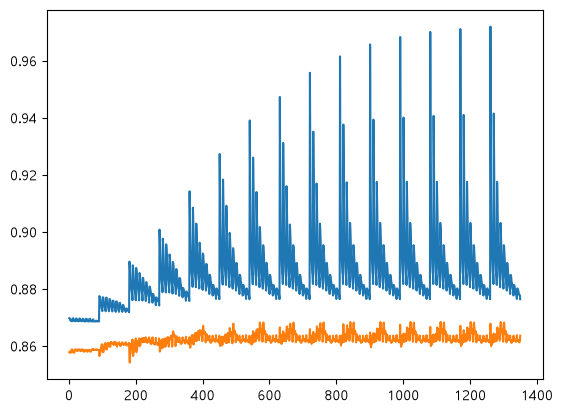

TypeError: 'NoneType' object is not callable

In [11]:
plt.plot(alist,gs.cv_results_['mean_train_score'])
plt.plot(alist,gs.cv_results_['mean_test_score'])
plt.show()()